In [1]:
import subprocess, sys, importlib.util
for _pkg in ["lifelines", "gseapy"]:                       # auto-install missing packages
    if importlib.util.find_spec(_pkg) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])

import os, random, tarfile, urllib.request, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score
from lifelines import KaplanMeierFitter
from lifelines.utils import concordance_index
from lifelines.statistics import logrank_test
import gseapy as gp

warnings.filterwarnings("ignore")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# ---------------- CONFIG ----------------
HORIZON_MONTHS = 120            # administrative censoring at 10 years for BOTH cohorts
SEEDS = [0, 1, 2]               # 3 seeds -> mean +/- std
PATHWAY_LIBS = ["MSigDB_Hallmark_2020", "KEGG_2021_Human"]
MIN_GENES_PER_PATHWAY = 10
KINDS = ["linear", "dense", "random_mask", "pathway"]
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)

# ---------------- HELPERS ----------------
def clean_survival(time_m, event):
    df = pd.DataFrame({"time": time_m, "event": event}).dropna()
    df = df[df["time"] > 0].copy()
    over = df["time"] > HORIZON_MONTHS
    df.loc[over, "event"] = 0
    df.loc[over, "time"] = HORIZON_MONTHS
    df["event"] = df["event"].astype(int)
    return df

def zscore(df):
    sd = df.std(ddof=0).replace(0, np.nan)
    return ((df - df.mean()) / sd).fillna(0.0)

def prepare_cohort_genes(df, max_nan_frac=0.1):
    """samples x genes -> drop genes with many NaN, median-impute the rest."""
    keep = df.columns[df.isna().mean() <= max_nan_frac]
    df = df[keep]
    return df.fillna(df.median())

def build_inputs(tcga_expr, mb_expr, pathways, min_genes=MIN_GENES_PER_PATHWAY):
    pathway_genes = set().union(*pathways.values())
    common = sorted(set(tcga_expr.columns) & set(mb_expr.columns) & pathway_genes)
    T = prepare_cohort_genes(tcga_expr[common])
    M = prepare_cohort_genes(mb_expr[common])
    valid = sorted(set(T.columns) & set(M.columns))
    valid = [g for g in valid if T[g].std() > 1e-6 and M[g].std() > 1e-6]
    valid_set = set(valid)
    kept = {k: sorted(set(v) & valid_set) for k, v in pathways.items()}
    kept = {k: v for k, v in kept.items() if len(v) >= min_genes}
    genes = sorted(set().union(*kept.values()))
    names = sorted(kept)
    gidx = {g: i for i, g in enumerate(genes)}
    mask = np.zeros((len(names), len(genes)), dtype=np.float32)
    for i, n in enumerate(names):
        for g in kept[n]:
            mask[i, gidx[g]] = 1.0
    Xt = zscore(T[genes]).values.astype(np.float32)   # per-cohort standardisation
    Xm = zscore(M[genes]).values.astype(np.float32)
    return Xt, Xm, mask, genes, names, T.index, M.index

def random_mask_like(mask, rng):
    out = np.zeros_like(mask)
    G = mask.shape[1]
    for i, n in enumerate(mask.sum(1).astype(int)):
        out[i, rng.choice(G, n, replace=False)] = 1.0
    return out

def five_year_auc(t, e, risk, horizon=60):
    known = (t >= horizon) | (e == 1)
    y = ((t < horizon) & (e == 1)).astype(int)[known]
    if y.min() == y.max():
        return np.nan
    return roc_auc_score(y, risk[known])

def download_any(urls, dest):
    if os.path.exists(dest) and os.path.getsize(dest) > 1000:
        return dest
    last = None
    for url in urls:
        try:
            print("Downloading", url)
            urllib.request.urlretrieve(url, dest)
            return dest
        except Exception as ex:
            last = ex
    raise RuntimeError(f"Download failed ({last}).")

def read_table_auto(path, **kw):
    with open(path, "rb") as f:
        gz = f.read(2) == b"\x1f\x8b"
    return pd.read_csv(path, sep="\t", compression="gzip" if gz else None, **kw)

# ---------------- TCGA-BRCA (UCSC Xena) ----------------
XENA = "https://tcga.xenahubs.net/download"
p_expr = download_any([f"{XENA}/TCGA.BRCA.sampleMap/HiSeqV2.gz"], "data/tcga_brca_expr.gz")
p_surv = download_any([f"{XENA}/survival/BRCA_survival.txt.gz", f"{XENA}/survival/BRCA_survival.txt"],
                      "data/tcga_brca_survival.txt")

tcga_expr = read_table_auto(p_expr, index_col=0).T          # samples x genes (log2 RSEM+1)
tcga_expr = tcga_expr.loc[:, ~tcga_expr.columns.duplicated()]
tcga_expr = tcga_expr[tcga_expr.index.str.endswith("-01")]    # primary tumours only
surv = read_table_auto(p_surv, index_col=0)
assert {"OS", "OS.time"} <= set(surv.columns), f"Unexpected survival columns: {list(surv.columns)}"

s = surv.loc[surv.index.isin(tcga_expr.index), ["OS.time", "OS"]]
tcga_clin = clean_survival(s["OS.time"] / 30.4375, s["OS"])   # days -> months
tcga_expr = tcga_expr.loc[tcga_clin.index]
print("TCGA:", tcga_expr.shape, "| events:", int(tcga_clin.event.sum()),
      "| median follow-up (mo):", round(tcga_clin.time.median(), 1))

Device: cuda
TCGA: (1081, 20530) | events: 139 | median follow-up (mo): 28.4


In [2]:
import os, glob, shutil, subprocess, tarfile, urllib.request
import numpy as np, pandas as pd

MB_DIR = "data/brca_metabric"
os.makedirs(MB_DIR, exist_ok=True)

def _is_real(path, min_bytes):
    if not os.path.exists(path) or os.path.getsize(path) < min_bytes:
        return False
    with open(path, "rb") as f:
        return not f.read(100).startswith(b"version https://git-lfs")   # LFS pointer = not real data

def _expr_file():
    c = [p for p in glob.glob(f"{MB_DIR}/data_mrna*microarray*.txt")
         if "zscore" not in os.path.basename(p).lower() and _is_real(p, 100_000)]
    return sorted(c, key=lambda p: ("illumina" not in p, p))[0] if c else None

def _have():
    return _expr_file() is not None and _is_real(f"{MB_DIR}/data_clinical_patient.txt", 5_000)

def _get(url, dest):
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=300) as r, open(dest, "wb") as f:
            shutil.copyfileobj(r, f)
        return True
    except Exception as ex:
        print("   failed:", str(ex)[:120])
        if os.path.exists(dest):
            os.remove(dest)
        return False

def _ingest(folder):                       # copy every .txt found under folder into MB_DIR
    for root, _, fs in os.walk(folder):
        for fn in fs:
            if fn.endswith(".txt"):
                shutil.copy(os.path.join(root, fn), os.path.join(MB_DIR, fn))

def _untar(path):
    shutil.rmtree("data/_tmp", ignore_errors=True)
    with tarfile.open(path) as tf:
        try:
            tf.extractall("data/_tmp", filter="data")
        except TypeError:
            tf.extractall("data/_tmp")
    _ingest("data/_tmp"); shutil.rmtree("data/_tmp", ignore_errors=True)

# ---- Method A: tarball from cBioPortal ----
if not _have():
    print("Trying https://datahub.assets.cbioportal.org/brca_metabric.tar.gz")
    if _get("https://datahub.assets.cbioportal.org/brca_metabric.tar.gz", "data/brca_metabric.tar.gz") \
            and tarfile.is_tarfile("data/brca_metabric.tar.gz"):
        _untar("data/brca_metabric.tar.gz")

# ---- Method B: the individual files from the cBioPortal DataHub on GitHub ----
if not _have():
    print("Trying GitHub DataHub files ...")
    bases = ["https://media.githubusercontent.com/media/cBioPortal/datahub/master/public/brca_metabric/",
             "https://raw.githubusercontent.com/cBioPortal/datahub/master/public/brca_metabric/"]
    for fn in ["data_clinical_patient.txt", "data_mrna_illumina_microarray.txt", "data_mrna_agilent_microarray.txt"]:
        dest = f"{MB_DIR}/{fn}"
        if _is_real(dest, 5_000):
            continue
        for b in bases:
            if _get(b + fn, dest) and _is_real(dest, 5_000):
                break
            if os.path.exists(dest):
                os.remove(dest)

# ---- Method C: official DataHub git-lfs download (sparse checkout of one study) ----
if not _have():
    print("Trying git sparse checkout of the DataHub (takes 1-3 min) ...")
    for c in ["apt-get -qq install -y git-lfs > /dev/null 2>&1 || true",
              "rm -rf data/_dh && git clone -q --depth 1 --filter=blob:none --sparse https://github.com/cBioPortal/datahub.git data/_dh",
              "cd data/_dh && git sparse-checkout set public/brca_metabric",
              "cd data/_dh && git lfs install --local && git lfs pull -I public/brca_metabric"]:
        subprocess.run(c, shell=True)
    if os.path.isdir("data/_dh/public/brca_metabric"):
        _ingest("data/_dh/public/brca_metabric")
    shutil.rmtree("data/_dh", ignore_errors=True)

# ---- Method D: manual upload (last resort) ----
if not _have():
    print("\nAUTOMATIC DOWNLOAD FAILED. Upload manually (either option):\n"
          "  Option 1: brca_metabric.tar.gz\n"
          "  Option 2: the two files data_mrna_illumina_microarray.txt and data_clinical_patient.txt")
    from google.colab import files
    for name in files.upload():
        if name.endswith((".tar.gz", ".tgz")):
            _untar(name)
        else:
            shutil.move(name, os.path.join(MB_DIR, os.path.basename(name)))

assert _have(), f"METABRIC files still missing. Found: {os.listdir(MB_DIR)}"
expr_path = _expr_file()
print("Using expression file:", os.path.basename(expr_path))

mb = pd.read_csv(expr_path, sep="\t")
mb = mb.drop(columns=[c for c in ["Entrez_Gene_Id"] if c in mb.columns]).dropna(subset=["Hugo_Symbol"])
mb_expr = mb.groupby("Hugo_Symbol").mean().T                  # samples x genes

raw = pd.read_csv(f"{MB_DIR}/data_clinical_patient.txt", sep="\t", comment="#").set_index("PATIENT_ID")
assert {"OS_MONTHS", "OS_STATUS"} <= set(raw.columns), list(raw.columns)
ev = raw["OS_STATUS"].astype(str).str.startswith("1").astype(float)   # "1:DECEASED" -> 1
ev[raw["OS_STATUS"].isna()] = np.nan
mb_clin = clean_survival(pd.to_numeric(raw["OS_MONTHS"], errors="coerce"), ev)

common_s = mb_clin.index.intersection(mb_expr.index)
mb_clin, mb_expr = mb_clin.loc[common_s], mb_expr.loc[common_s]
print("METABRIC:", mb_expr.shape, "| events:", int(mb_clin.event.sum()),
      "| median follow-up (mo):", round(mb_clin.time.median(), 1))

Trying https://datahub.assets.cbioportal.org/brca_metabric.tar.gz
Using expression file: data_mrna_illumina_microarray.txt
METABRIC: (1979, 20385) | events: 760 | median follow-up (mo): 116.5


In [3]:
assert "tcga_clin" in globals() and "mb_clin" in globals() and "build_inputs" in globals(), \
    "Run the earlier big cell (it defines helpers + TCGA) and Cell 1 first"

pathways = {}
for lib in PATHWAY_LIBS:
    d = gp.get_library(name=lib, organism="Human")
    for k, genes in d.items():
        pathways[f"{lib.split('_')[0]}:{k}"] = sorted(set(genes))
print("Pathways loaded:", len(pathways))

X_t, X_m, MASK, GENES, PATH_NAMES, _, _ = build_inputs(tcga_expr, mb_expr, pathways, MIN_GENES_PER_PATHWAY)
t_t, e_t = tcga_clin.time.values.astype(float), tcga_clin.event.values.astype(int)
t_m, e_m = mb_clin.time.values.astype(float), mb_clin.event.values.astype(int)
print(f"genes={len(GENES)}  pathways={len(PATH_NAMES)}  TCGA={X_t.shape}  METABRIC={X_m.shape}")
assert len(X_t) == len(t_t) and len(X_m) == len(t_m)

Pathways loaded: 370
genes=8588  pathways=361  TCGA=(1081, 8588)  METABRIC=(1979, 8588)


In [4]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

class MaskedLinear(nn.Linear):
    def __init__(self, in_f, out_f, mask):               # mask: (out_f, in_f) of 0/1
        super().__init__(in_f, out_f)
        self.register_buffer("mask", torch.as_tensor(mask, dtype=torch.float32))
    def forward(self, x):
        return nn.functional.linear(x, self.weight * self.mask, self.bias)

class CoxNet(nn.Module):
    """genes -> (masked) pathway nodes -> small MLP -> log-risk"""
    def __init__(self, mask, hidden=32, p_in=0.2, p=0.3):
        super().__init__()
        P, G = mask.shape
        self.drop_in = nn.Dropout(p_in)
        self.g2p = MaskedLinear(G, P, mask)
        self.head = nn.Sequential(nn.ReLU(), nn.Dropout(p), nn.Linear(P, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, x):
        return self.head(self.g2p(self.drop_in(x))).squeeze(-1)

class LinearCox(nn.Module):
    def __init__(self, G):
        super().__init__()
        self.lin = nn.Linear(G, 1)
    def forward(self, x):
        return self.lin(x).squeeze(-1)

def make_model(kind, mask, rng):
    if kind == "pathway":     return CoxNet(mask)
    if kind == "random_mask": return CoxNet(random_mask_like(mask, rng))   # same sparsity, shuffled biology
    if kind == "dense":       return CoxNet(np.ones_like(mask))            # same size, no biology
    if kind == "linear":      return LinearCox(mask.shape[1])              # Cox lasso-style baseline
    raise ValueError(kind)

def cox_ph_loss(risk, time, event):
    order = torch.argsort(time, descending=True)
    risk, event = risk[order], event[order]
    log_cum = torch.logcumsumexp(risk, dim=0)
    return -((risk - log_cum) * event).sum() / event.sum().clamp(min=1.0)

def T(a):
    return torch.as_tensor(np.asarray(a), dtype=torch.float32, device=DEVICE)

def train_cox(kind, mask, Xtr, ttr, etr, Xva, tva, eva, seed,
              max_epochs=200, patience=20, lr=1e-3, wd=1e-3, l1=1e-3):
    set_seed(seed)
    model = make_model(kind, mask, np.random.default_rng(seed)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    Xtr_, ttr_, etr_, Xva_ = T(Xtr), T(ttr), T(etr), T(Xva)
    best, bad, best_state = -1.0, 0, None
    for ep in range(max_epochs):
        model.train(); opt.zero_grad()
        loss = cox_ph_loss(model(Xtr_), ttr_, etr_)
        if kind == "linear":
            loss = loss + l1 * model.lin.weight.abs().sum()       # lasso part
        loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            rv = model(Xva_).cpu().numpy()
        c = concordance_index(tva, -rv, eva)
        if c > best + 1e-4:
            best, bad = c, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    return model, best

@torch.no_grad()
def predict_risk(model, X):
    model.eval()
    return model(T(X)).cpu().numpy()

# quick smoke test (about 10 seconds): one pathway model, one split
tr2, va2 = train_test_split(np.arange(len(X_t)), test_size=0.15, stratify=e_t, random_state=0)
_m, _best = train_cox("pathway", MASK, X_t[tr2], t_t[tr2], e_t[tr2], X_t[va2], t_t[va2], e_t[va2], 0, max_epochs=30)
print("Smoke test OK | val C-index:", round(_best, 3),
      "| external C-index:", round(concordance_index(t_m, -predict_risk(_m, X_m), e_m), 3))

Smoke test OK | val C-index: 0.684 | external C-index: 0.587


In [5]:
import time as _time
rows, ext = [], {}
for seed in SEEDS:
    skf = StratifiedKFold(5, shuffle=True, random_state=seed)
    for kind in KINDS:
        t0 = _time.time()
        cs = []
        for tr, te in skf.split(X_t, e_t):
            tr2, va2 = train_test_split(tr, test_size=0.15, stratify=e_t[tr], random_state=seed)
            m, _ = train_cox(kind, MASK, X_t[tr2], t_t[tr2], e_t[tr2], X_t[va2], t_t[va2], e_t[va2], seed)
            cs.append(concordance_index(t_t[te], -predict_risk(m, X_t[te]), e_t[te]))
        # train on all TCGA (85/15 train/val for early stopping) -> test on METABRIC, no retraining
        tr2, va2 = train_test_split(np.arange(len(X_t)), test_size=0.15, stratify=e_t, random_state=seed)
        m, _ = train_cox(kind, MASK, X_t[tr2], t_t[tr2], e_t[tr2], X_t[va2], t_t[va2], e_t[va2], seed)
        risk_m = predict_risk(m, X_m)
        ext[(kind, seed)] = (m, risk_m)
        rows.append(dict(model=kind, seed=seed,
                         internal_cindex=float(np.mean(cs)),
                         external_cindex=concordance_index(t_m, -risk_m, e_m),
                         external_auc5y=five_year_auc(t_m, e_m, risk_m)))
        print(f"seed={seed} {kind:12s} internal={rows[-1]['internal_cindex']:.3f} "
              f"external={rows[-1]['external_cindex']:.3f}  ({_time.time()-t0:.0f}s)")
res = pd.DataFrame(rows)
res.to_csv("results/per_seed_results.csv", index=False)

seed=0 linear       internal=0.653 external=0.588  (2s)
seed=0 dense        internal=0.617 external=0.596  (4s)
seed=0 random_mask  internal=0.668 external=0.602  (5s)
seed=0 pathway      internal=0.676 external=0.576  (5s)
seed=1 linear       internal=0.709 external=0.566  (2s)
seed=1 dense        internal=0.676 external=0.605  (3s)
seed=1 random_mask  internal=0.640 external=0.599  (3s)
seed=1 pathway      internal=0.698 external=0.611  (3s)
seed=2 linear       internal=0.668 external=0.591  (1s)
seed=2 dense        internal=0.664 external=0.586  (2s)
seed=2 random_mask  internal=0.648 external=0.595  (3s)
seed=2 pathway      internal=0.646 external=0.590  (3s)



            internal_cindex        external_cindex        external_auc5y       
                       mean    std            mean    std           mean    std
model                                                                          
linear                0.677  0.029           0.582  0.014          0.600  0.032
dense                 0.652  0.031           0.596  0.009          0.624  0.010
random_mask           0.652  0.014           0.599  0.004          0.631  0.008
pathway               0.673  0.026           0.592  0.017          0.621  0.023


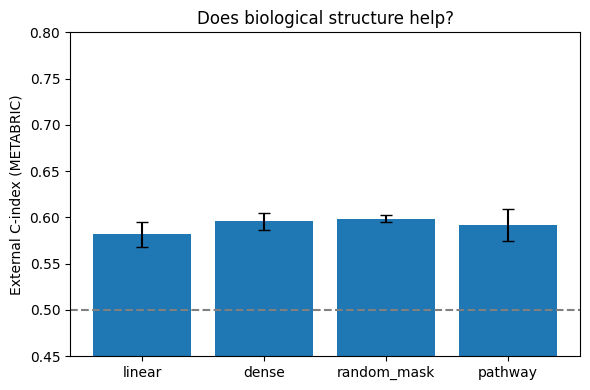

Pathway model METABRIC C-index 95% CI: [0.555 0.596]


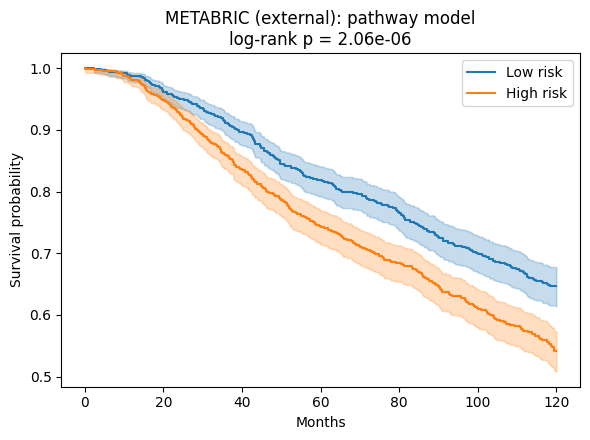

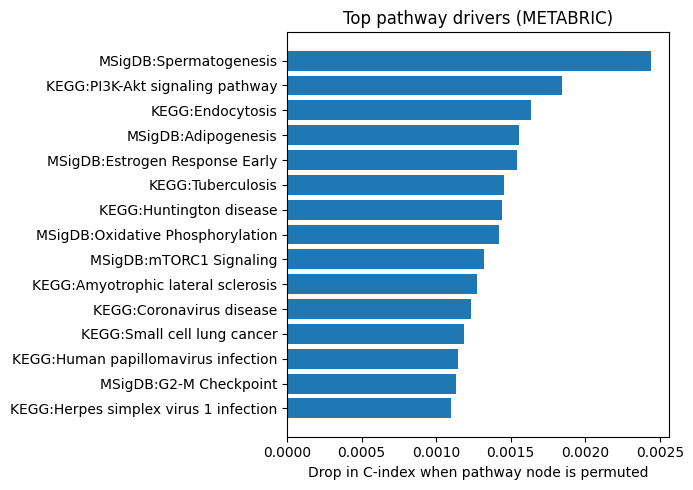


                              pathway  delta_cindex
               MSigDB:Spermatogenesis      0.002439
      KEGG:PI3K-Akt signaling pathway      0.001842
                     KEGG:Endocytosis      0.001637
                  MSigDB:Adipogenesis      0.001553
       MSigDB:Estrogen Response Early      0.001542
                    KEGG:Tuberculosis      0.001457
              KEGG:Huntington disease      0.001441
     MSigDB:Oxidative Phosphorylation      0.001422
              MSigDB:mTORC1 Signaling      0.001322
   KEGG:Amyotrophic lateral sclerosis      0.001271
             KEGG:Coronavirus disease      0.001233
          KEGG:Small cell lung cancer      0.001186
  KEGG:Human papillomavirus infection      0.001146
               MSigDB:G2-M Checkpoint      0.001132
KEGG:Herpes simplex virus 1 infection      0.001103

DONE. Files in ./results/ : ['ablation_external_cindex.png', 'genes.csv', 'km_metabric_pathway.png', 'pathway_importance.csv', 'pathway_importance.png', 'pathway_mask

In [6]:
# ---------- Summary table + ablation figure ----------
summary = res.groupby("model")[["internal_cindex", "external_cindex", "external_auc5y"]].agg(["mean", "std"]).round(3)
summary = summary.loc[KINDS]
summary.to_csv("results/summary.csv")
print("\n" + summary.to_string())

fig, ax = plt.subplots(figsize=(6, 4))
mu = res.groupby("model")["external_cindex"].mean().loc[KINDS]
sd = res.groupby("model")["external_cindex"].std().fillna(0).loc[KINDS]
ax.bar(KINDS, mu.values, yerr=sd.values, capsize=4)
ax.axhline(0.5, ls="--", c="gray"); ax.set_ylim(0.45, max(0.8, mu.max() + 0.05))
ax.set_ylabel("External C-index (METABRIC)"); ax.set_title("Does biological structure help?")
fig.tight_layout(); fig.savefig("results/ablation_external_cindex.png", dpi=200); plt.show()

# ---------- bootstrap CI for the pathway model ----------
def bootstrap_ci(t, e, risk, n=500, seed=0):
    rng = np.random.default_rng(seed); vals = []
    for _ in range(n):
        i = rng.integers(0, len(t), len(t))
        vals.append(concordance_index(t[i], -risk[i], e[i]))
    return np.percentile(vals, [2.5, 97.5])
m_path, risk_path = ext[("pathway", SEEDS[0])]
print("Pathway model METABRIC C-index 95% CI:", bootstrap_ci(t_m, e_m, risk_path).round(3))

# ---------- Kaplan-Meier curves ----------
def km_plot(t, e, risk, title, path):
    hi = risk > np.median(risk)
    kmf = KaplanMeierFitter()
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for flag, label in [(False, "Low risk"), (True, "High risk")]:
        kmf.fit(t[hi == flag], e[hi == flag], label=label)
        kmf.plot_survival_function(ax=ax, ci_show=True)
    p = logrank_test(t[hi], t[~hi], e[hi], e[~hi]).p_value
    ax.set_title(f"{title}\nlog-rank p = {p:.2e}")
    ax.set_xlabel("Months"); ax.set_ylabel("Survival probability")
    fig.tight_layout(); fig.savefig(path, dpi=200); plt.show()
    return p
p_km = km_plot(t_m, e_m, risk_path, "METABRIC (external): pathway model", "results/km_metabric_pathway.png")

# ---------- Pathway importance (permute one pathway node, external cohort) ----------
@torch.no_grad()
def pathway_importance(model, X, t, e, names, n_rep=5, seed=0):
    rng = np.random.default_rng(seed)
    model.eval()
    H = model.g2p(T(X))                                   # (n, P) pathway activations
    base = concordance_index(t, -model.head(H).squeeze(-1).cpu().numpy(), e)
    out = []
    for p in range(H.shape[1]):
        drops = []
        for _ in range(n_rep):
            Hp = H.clone()
            perm = torch.as_tensor(rng.permutation(len(Hp)), device=H.device)
            Hp[:, p] = H[perm, p]
            drops.append(base - concordance_index(t, -model.head(Hp).squeeze(-1).cpu().numpy(), e))
        out.append((names[p], float(np.mean(drops))))
    return pd.DataFrame(out, columns=["pathway", "delta_cindex"]).sort_values("delta_cindex", ascending=False)

imp = pathway_importance(m_path, X_m, t_m, e_m, PATH_NAMES)
imp.to_csv("results/pathway_importance.csv", index=False)
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top["pathway"], top["delta_cindex"])
ax.set_xlabel("Drop in C-index when pathway node is permuted")
ax.set_title("Top pathway drivers (METABRIC)")
fig.tight_layout(); fig.savefig("results/pathway_importance.png", dpi=200); plt.show()
print("\n" + imp.head(15).to_string(index=False))

# ---------- Save artifacts ----------
torch.save(m_path.state_dict(), "results/pathway_model.pt")
np.save("results/pathway_mask.npy", MASK)
pd.Series(GENES).to_csv("results/genes.csv", index=False, header=False)
pd.Series(PATH_NAMES).to_csv("results/pathways.csv", index=False, header=False)
print("\nDONE. Files in ./results/ :", sorted(os.listdir("results")))

In [7]:
import shutil
from google.colab import files
shutil.make_archive("results", "zip", "results")
files.download("results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
def paired_boot_diff(t, e, r1, r2, n=300, seed=0):
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        i = rng.integers(0, len(t), len(t))
        d.append(concordance_index(t[i], -r1[i], e[i]) - concordance_index(t[i], -r2[i], e[i]))
    d = np.array(d)
    return d.mean(), np.percentile(d, [2.5, 97.5])

for seed in SEEDS:
    for other in ["random_mask", "dense", "linear"]:
        mean_d, ci = paired_boot_diff(t_m, e_m, ext[("pathway", seed)][1], ext[(other, seed)][1])
        print(f"seed={seed} pathway - {other:12s}: {mean_d:+.3f}  95% CI [{ci[0]:+.3f}, {ci[1]:+.3f}]")

seed=0 pathway - random_mask : -0.027  95% CI [-0.042, -0.012]
seed=0 pathway - dense       : -0.021  95% CI [-0.032, -0.008]
seed=0 pathway - linear      : -0.012  95% CI [-0.027, +0.000]
seed=1 pathway - random_mask : +0.011  95% CI [-0.001, +0.022]
seed=1 pathway - dense       : +0.006  95% CI [-0.009, +0.021]
seed=1 pathway - linear      : +0.045  95% CI [+0.026, +0.068]
seed=2 pathway - random_mask : -0.005  95% CI [-0.014, +0.003]
seed=2 pathway - dense       : +0.003  95% CI [-0.016, +0.017]
seed=2 pathway - linear      : -0.001  95% CI [-0.015, +0.014]


In [9]:
rows_rev = []
for seed in SEEDS:
    for kind in KINDS:
        tr, va = train_test_split(np.arange(len(X_m)), test_size=0.15, stratify=e_m, random_state=seed)
        m, _ = train_cox(kind, MASK, X_m[tr], t_m[tr], e_m[tr], X_m[va], t_m[va], e_m[va], seed)
        r = predict_risk(m, X_t)
        rows_rev.append(dict(model=kind, seed=seed,
                             external_cindex=concordance_index(t_t, -r, e_t),
                             external_auc5y=five_year_auc(t_t, e_t, r)))
        print(f"seed={seed} {kind:12s} METABRIC->TCGA C-index={rows_rev[-1]['external_cindex']:.3f}")
rev = pd.DataFrame(rows_rev)
print("\n" + rev.groupby("model")[["external_cindex", "external_auc5y"]].agg(["mean", "std"]).round(3).loc[KINDS].to_string())
rev.to_csv("results/reverse_direction_results.csv", index=False)

seed=0 linear       METABRIC->TCGA C-index=0.688
seed=0 dense        METABRIC->TCGA C-index=0.670
seed=0 random_mask  METABRIC->TCGA C-index=0.678
seed=0 pathway      METABRIC->TCGA C-index=0.678
seed=1 linear       METABRIC->TCGA C-index=0.683
seed=1 dense        METABRIC->TCGA C-index=0.688
seed=1 random_mask  METABRIC->TCGA C-index=0.688
seed=1 pathway      METABRIC->TCGA C-index=0.686
seed=2 linear       METABRIC->TCGA C-index=0.681
seed=2 dense        METABRIC->TCGA C-index=0.692
seed=2 random_mask  METABRIC->TCGA C-index=0.721
seed=2 pathway      METABRIC->TCGA C-index=0.695

            external_cindex        external_auc5y       
                       mean    std           mean    std
model                                                   
linear                0.684  0.004          0.694  0.005
dense                 0.683  0.011          0.702  0.007
random_mask           0.696  0.022          0.711  0.020
pathway               0.686  0.009          0.703  0.011


In [10]:
from scipy.stats import wilcoxon
rows9 = []
for seed in range(10):
    for kind in KINDS:
        tr, va = train_test_split(np.arange(len(X_m)), test_size=0.15, stratify=e_m, random_state=seed)
        m, _ = train_cox(kind, MASK, X_m[tr], t_m[tr], e_m[tr], X_m[va], t_m[va], e_m[va], seed)
        r = predict_risk(m, X_t)
        rows9.append(dict(model=kind, seed=seed, cindex=concordance_index(t_t, -r, e_t)))
    print("seed", seed, "done")
r9 = pd.DataFrame(rows9)
r9.to_csv("results/reverse_10seeds.csv", index=False)
piv = r9.pivot(index="seed", columns="model", values="cindex")[KINDS]
print("\n" + piv.agg(["mean", "std"]).round(3).to_string())
for other in ["random_mask", "dense", "linear"]:
    d = piv["pathway"] - piv[other]
    print(f"pathway - {other:12s}: mean diff {d.mean():+.3f}, pathway wins {int((d > 0).sum())}/10, "
          f"Wilcoxon p = {wilcoxon(d).pvalue:.3f}")

seed 0 done
seed 1 done
seed 2 done
seed 3 done
seed 4 done
seed 5 done
seed 6 done
seed 7 done
seed 8 done
seed 9 done

model  linear  dense  random_mask  pathway
mean    0.677  0.664        0.677    0.669
std     0.014  0.030        0.028    0.025
pathway - random_mask : mean diff -0.008, pathway wins 1/10, Wilcoxon p = 0.014
pathway - dense       : mean diff +0.005, pathway wins 7/10, Wilcoxon p = 0.084
pathway - linear      : mean diff -0.008, pathway wins 4/10, Wilcoxon p = 0.375


In [ ]:
import os, json, shutil
import numpy as np, pandas as pd

# ---------- EDIT THESE ----------
GH_USER = "tehreemraouf-06"
REPO = "pathway-cox-tcga-metabric"
PROJECT_TITLE = "Do biological pathway priors improve cross-cohort survival prediction in breast cancer?"
# --------------------------------

def ms(x):                                            # "mean ± std"
    return f"{x.mean():.3f} ± {x.std():.3f}"

def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "|".join("---" for _ in header) + "|"]
    out += ["| " + " | ".join(r) + " |" for r in rows]
    return "\n".join(out)

order = ["linear", "dense", "random_mask", "pathway"]
names = {"linear": "Cox-lasso (linear)", "dense": "Dense net (no biology)",
         "random_mask": "Random-mask net (control)", "pathway": "Pathway-masked net"}

fwd = pd.read_csv("results/per_seed_results.csv")
rows = []
for k in order:
    d = fwd[fwd.model == k]
    rows.append([names[k], ms(d.internal_cindex), ms(d.external_cindex), ms(d.external_auc5y.dropna())])
fwd_table = md_table(["Model", "Internal C-index (TCGA, 5-fold CV)", "External C-index (TCGA→METABRIC)", "External 5-yr AUC"], rows)

rev_section = ""
if os.path.exists("results/reverse_direction_results.csv"):
    rev = pd.read_csv("results/reverse_direction_results.csv")
    rows = [[names[k], ms(rev[rev.model == k].external_cindex), ms(rev[rev.model == k].external_auc5y.dropna())] for k in order]
    rev_section = ("### Reverse direction (train METABRIC → test TCGA)\n\n"
                   + md_table(["Model", "External C-index", "External 5-yr AUC"], rows) + "\n\n")
if os.path.exists("results/reverse_10seeds.csv"):
    r10 = pd.read_csv("results/reverse_10seeds.csv")
    rows = [[names[k], ms(r10[r10.model == k].cindex)] for k in order]
    rev_section += ("### Reverse direction, 10 seeds\n\n"
                    + md_table(["Model", "External C-index (mean ± sd over 10 seeds)"], rows) + "\n\n")

try:
    n_t, ev_t = f"{len(tcga_clin):,}", f"{int(tcga_clin.event.sum()):,}"
    n_m, ev_m = f"{len(mb_clin):,}", f"{int(mb_clin.event.sum()):,}"
except NameError:
    n_t = ev_t = n_m = ev_m = "n/a"
try:
    n_g, n_p = f"{len(GENES):,}", f"{len(PATH_NAMES):,}"
except NameError:
    n_g = n_p = "n/a"

readme = f"""# {PROJECT_TITLE}

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/{GH_USER}/{REPO}/blob/main/pathway_cox.ipynb)

## Research question
Does constraining a neural Cox survival model with biological pathway structure (MSigDB Hallmark + KEGG)
improve generalization from one breast-cancer cohort to an independent cohort, compared with models that
ignore the biology?

## Data (all free and public)
| Cohort | Source | Patients | Deaths |
|---|---|---|---|
| TCGA-BRCA (RNA-seq, primary tumours) | UCSC Xena | {n_t} | {ev_t} |
| METABRIC (microarray) | cBioPortal DataHub | {n_m} | {ev_m} |

Pathways: MSigDB Hallmark 2020 and KEGG 2021 Human via `gseapy`. After filtering: **{n_g} genes, {n_p} pathways** shared by both cohorts.
Endpoint: overall survival, administratively censored at 10 years in both cohorts.

## Methods
- Per-cohort gene z-scoring (separate scaling for each cohort to reduce platform differences)
- All networks use the same Cox partial-likelihood loss and early stopping on a validation split
- **Pathway-masked net:** genes → pathway nodes (connections allowed only for known membership) → small MLP → risk
- **Controls:** Cox-lasso baseline, dense net (same size, no biology), random-mask net (same sparsity, shuffled gene membership)
- Internal evaluation: 5-fold CV on TCGA. External evaluation: train on one cohort, test on the other without retraining
- 3 random seeds; metrics: concordance index (C-index) and 5-year AUC

## Results
### Train TCGA → test METABRIC

{fwd_table}

{rev_section}### Figures
![Ablation](results/ablation_external_cindex.png)
![Kaplan-Meier](results/km_metabric_pathway.png)
![Pathway importance](results/pathway_importance.png)

## Key finding
Pathway structure did **not** give a consistent improvement over a random-mask control, a dense network, or a
simple Cox-lasso. Differences between models were smaller than seed-to-seed variation in both transfer directions.
Transfer performance depended mainly on direction: training on the larger METABRIC cohort gave
C-index of about 0.69 on TCGA, whereas training on TCGA gave about 0.59 on METABRIC, which suggests training-set
size and number of events limit performance more than model architecture does.

## Limitations
- TCGA has few events and short follow-up; test-set confidence intervals are wide
- RNA-seq vs microarray platform shift is only partly handled by per-cohort scaling
- METABRIC overall survival includes non-cancer deaths
- Hyperparameters were not extensively tuned; only 3 seeds in the main experiment
- The random-mask control keeps the same sparsity, so it may act as a regulariser rather than a pure "no biology" control
- Pathway-importance scores are very small and exploratory, not evidence of causal drivers

## Reproduce
1. Open `pathway_cox.ipynb` in Google Colab (GPU runtime)
2. Run the cells in order (data are downloaded automatically)

## Data sources and references
- TCGA via UCSC Xena (Goldman et al., Nat Biotechnol 2020)
- METABRIC (Curtis et al., Nature 2012) via cBioPortal
- MSigDB Hallmark gene sets (Liberzon et al., Cell Systems 2015); KEGG
"""
open("README.md", "w", encoding="utf-8").write(readme)

open("requirements.txt", "w").write("torch\nlifelines\ngseapy\nscikit-learn\nscipy\npandas\nnumpy\nmatplotlib\n")
open(".gitignore", "w").write("data/\n__pycache__/\n*.tar.gz\n")

# save the current notebook (Colab feature); falls back gracefully
try:
    from google.colab import _message
    nb = _message.blocking_request("get_ipynb", request="", timeout_sec=300)["ipynb"]
    json.dump(nb, open("pathway_cox.ipynb", "w"))
    print("Notebook saved as pathway_cox.ipynb")
except Exception as ex:
    print("Could not auto-save notebook (", str(ex)[:80], ") -> download it via File > Download .ipynb and upload it to the repo later.")

print("README.md, requirements.txt, .gitignore created. Preview:\n")
print(readme[:1800])